# Geometry-aware attention for camera-set quality prediction: analysis

This notebook is the analysis and study guide for the experiments in `experiments/geometry-aware/`.
It imports the implementations instead of copying them:

| file | what it holds |
|---|---|
| `experiments/geometry-aware/geo_models.py` | PointNet, attention, geometry-aware attention, relations |
| `experiments/geometry-aware/run_experiments.py` | data, training loop, evaluation, baselines |
| `experiments/geometry-aware/run_all.sh` | the exact commands that produced `results/` |
| `experiments/geometry-aware/train_cached_models.py` | the geo model used for the attention maps (section 8) |
| `experiments/geometry-aware/test_geo_models.py` | correctness tests |
| `scripts/synthetic_coverage_gap.py` | the synthetic generator (unchanged) |
| `scripts/pilot_set_models.py` | the real-data loader (unchanged) |

**Labels used throughout.** <span style="color:#1f6feb">**SIMULATED**</span> marks results on synthetic camera
sets, where the target is an azimuthal coverage gap in degrees. <span style="color:#c0392b">**REAL**</span> marks
results on the 28 Metashape builds, where the target is the v3 surface-error label. The two are never mixed in
one figure.

Nothing expensive is retrained here. Results come from `experiments/geometry-aware/results/`; trained weights
from `runs/attention-maps/` (attention, PointNet) and `experiments/geometry-aware/results/models/` (geo).

In [2]:
%pip install xgboost

  Using cached xgboost-3.4.1-py3-none-macosx_12_0_arm64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-macosx_12_0_arm64.whl (2.4 MB)
Note: you may need to restart the kernel to use updated packages.


In [3]:
import sys, json, math, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

warnings.filterwarnings('ignore', category=UserWarning)

# Repository root = the folder that holds pyproject.toml, found from wherever the notebook runs.
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
EXP = REPO / 'experiments' / 'geometry-aware'
RES = EXP / 'results'
sys.path[:0] = [str(EXP), str(REPO / 'scripts')]

import geo_models as gm                 # the models
import run_experiments as E             # training, evaluation, data helpers
import synthetic_coverage_gap as syn    # synthetic generator (original)
import pilot_set_models as pilot        # real-data loader (original)

torch.set_num_threads(2)
torch.manual_seed(0)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})
SIM, REAL = '#1f6feb', '#c0392b'
COLOR = {'geo': '#c0392b', 'geo_inv': '#e67e22', 'geo_shuf': '#95a5a6', 'attention': '#2c3e50',
         'pointnet': '#7f8c8d', 'xgb_pair': '#8e44ad'}
print('repo:', REPO)
print('torch', torch.__version__)

repo: /Users/tristan/Documents/bd3d-reconstruction-quality
torch 2.15.0


## 1. Research motivation, hypothesis, and experimental design

**Problem.** Dense reconstruction is the slow step of photogrammetry (the 145-photo coffin reference took
3448 s). After alignment we already know every camera's position and viewing direction. Can the camera
layout alone predict how good the final mesh will be, before paying for dense reconstruction? The usual
quick check, reprojection RMSE, moves the *wrong way* in this repo's GPU builds (Spearman ρ = −0.68 for the
7 dog GPU builds, −0.90 for the 5 coffin builds; section 2b), because it measures how consistent the kept observations are, not whether the object is covered.

**Why set models.** A camera configuration is an unordered set of N cameras in an arbitrary frame. The model
must be (a) permutation-invariant and (b) insensitive to the rotation of the frame. PointNet and the existing
attention model meet (a) by max-pooling, and (b) approximately, by random-rotation augmentation.

**Hypothesis.** Coverage is relational: a gap is a large angular separation between neighbouring cameras.
Attention compares cameras only through dot products of learned embeddings of raw, randomly rotated
coordinates. If we instead *give* each attention head the rotation-invariant pairwise geometry (distance,
angular separation, view agreement) as a bias on its logits, the model should

- H1: predict coverage-dependent targets more accurately at a fixed training budget;
- H2: generalize better to camera counts not seen in training;
- H3: and the benefit should come from the geometry itself, not from the extra parameters (control: the same
  model with the geometry shuffled between camera pairs).

**Design.**

| experiment | data | question |
|---|---|---|
| localized | SIMULATED, two rings, gap in the upper ring only | H1, H3 |
| count_shift | SIMULATED, train 20–35 cameras, test 45–60 | H2 |
| long check | SIMULATED localized, 400 epochs, 3000 sets | is H1 about speed or ceiling? |
| real LOGO / LOAO | REAL, 28 builds, hold out a capture group / an object | does any of it show on real data? |

Configuration of each run is saved next to its results (`results/*/config.json`).

In [2]:
configs = {p.parent.name: json.loads(p.read_text()) for p in sorted(RES.glob('*/config.json'))}
keys = ['mode', 'conditions', 'schemes', 'seeds', 'epochs', 'lr', 'cosine', 'n_train', 'n_val', 'n_test', 'nets']
pd.DataFrame({k: {kk: configs[k].get(kk) for kk in keys} for k in configs}).T

,mode,conditions,schemes,seeds,epochs,lr,cosine,n_train,n_val,n_test,nets
real,real,"[global, localized, count_shift]","[LOGO, LOAO]","[0, 1, 2, 3, 4]",400,0.001,False,3000,600,600,"[pointnet, attention, geo, geo_inv, geo_shuf]"
synthetic-count-shift,synthetic,[count_shift],"[LOGO, LOAO]","[0, 1, 2]",150,0.003,True,2000,600,600,"[pointnet, attention, geo, geo_inv]"
synthetic-localized,synthetic,[localized],"[LOGO, LOAO]","[0, 1, 2]",150,0.003,True,2000,600,600,"[pointnet, attention, geo, geo_inv, geo_shuf]"
synthetic-localized-long,synthetic,[localized],"[LOGO, LOAO]",[0],400,0.001,False,3000,600,600,"[attention, geo]"


## 2. Dataset exploration

### 2a. <span style="color:#1f6feb">SIMULATED</span> camera configurations

`syn.make_set` places cameras on rings around an object at radius ≈ 5, cuts an azimuthal hole of 0–150°,
then puts the set in an arbitrary frame (random rotation, scale, offset) and removes what an unreferenced
alignment lets us remove: centroid and median distance. The target is the largest azimuthal gap.

- **global**: one elevation band (10–50°), 20–60 cameras.
- **localized**: a full lower ring (0–15°) plus an upper ring (40–55°) that has the hole; 10–30 cameras each.
  The target is the gap in the upper ring only, so the model has to tell the rings apart.
- **count_shift** (`E.make_set_n`): one band, train/val with 20–35 cameras, test with 45–60.

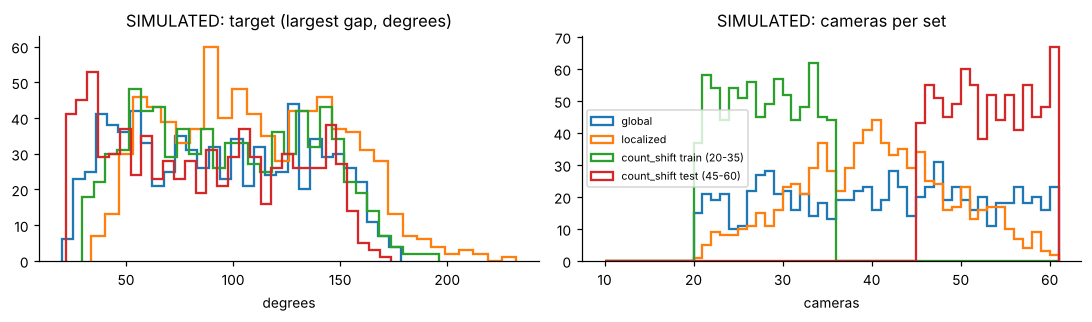

In [3]:
rng = np.random.default_rng(123)
samples = {c: [syn.make_set(rng, c) for _ in range(800)] for c in ('global', 'localized')}
samples['count_shift train (20-35)'] = [E.make_set_n(rng, 20, 35) for _ in range(800)]
samples['count_shift test (45-60)'] = [E.make_set_n(rng, 45, 60) for _ in range(800)]

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for name, s in samples.items():
    ax[0].hist([t for _, t in s], bins=30, histtype='step', lw=1.5, label=name)
    ax[1].hist([len(p) for p, _ in s], bins=np.arange(10, 62), histtype='step', lw=1.5, label=name)
ax[0].set(title='SIMULATED: target (largest gap, degrees)', xlabel='degrees')
ax[1].set(title='SIMULATED: cameras per set', xlabel='cameras')
ax[1].legend(fontsize=7)
plt.tight_layout()

### 2b. <span style="color:#c0392b">REAL</span> reconstruction builds

`pilot.load_runs` reads every build with a v3 label: 16 historical dog builds (CPU pipeline), 7 dog GPU
builds, 5 coffin builds. Each build's input is its `cameras.csv` (aligned cameras only), centred and divided
by the median camera distance, giving an (n, 6) array: position then view direction. Labels are the symmetric
surface RMSE against each object's reference build, as a fraction of its bounding-box diagonal (lower is
better; method in `docs/METHOD.md`).

In [4]:
runs = pilot.load_runs(REPO / 'results/pahma-5-613-v2/labels-all.csv')
for r in runs:
    r['group'] = r['artifact'] + '/' + r['source']
real = pd.DataFrame([{k: r[k] for k in ('group', 'run', 'n', 'label', 'reproj')} for r in runs])
print(len(real), 'builds')
display(real.groupby('group').agg(builds=('run', 'size'), cameras_min=('n', 'min'), cameras_max=('n', 'max'),
                                  label_mean=('label', 'mean'), label_min=('label', 'min'), label_max=('label', 'max')))
real.sort_values(['group', 'n'])

28 builds


,builds,cameras_min,cameras_max,label_mean,label_min,label_max
group,,,,,,
arf-dog/gpu-d8,7,10,38,0.009972,0.006211,0.022524
arf-dog/hist16-cpu,16,25,40,0.004397,0.003130,0.010679
pahma-5-613/gpu-d8,5,29,122,0.016486,0.008014,0.035386


,group,run,n,label,reproj
16,arf-dog/gpu-d8,random10,10,0.022524,0.245210
18,arf-dog/gpu-d8,random15_s20261110,15,0.008512,0.324626
19,arf-dog/gpu-d8,random15_s20261111,15,0.009122,0.329331
20,arf-dog/gpu-d8,random20_s20261110,20,0.007162,0.337140
21,arf-dog/gpu-d8,random20_s20261111,20,0.006211,0.363837
17,arf-dog/gpu-d8,side40,30,0.008491,0.432487
22,arf-dog/gpu-d8,side25,38,0.007779,0.452854
0,arf-dog/hist16-cpu,arf-dog-image-count-25-seed-20260822-v1,25,0.003450,0.250362
1,arf-dog/hist16-cpu,arf-dog-image-count-25-seed-20260823-v1,25,0.004044,0.250045
2,arf-dog/hist16-cpu,arf-dog-image-count-25-seed-20260824-v1,25,0.005470,0.247330


arf-dog/gpu-d8         Spearman(reproj, label) = -0.68  (n=7)
arf-dog/hist16-cpu     Spearman(reproj, label) = +0.10  (n=16)
pahma-5-613/gpu-d8     Spearman(reproj, label) = -0.90  (n=5)


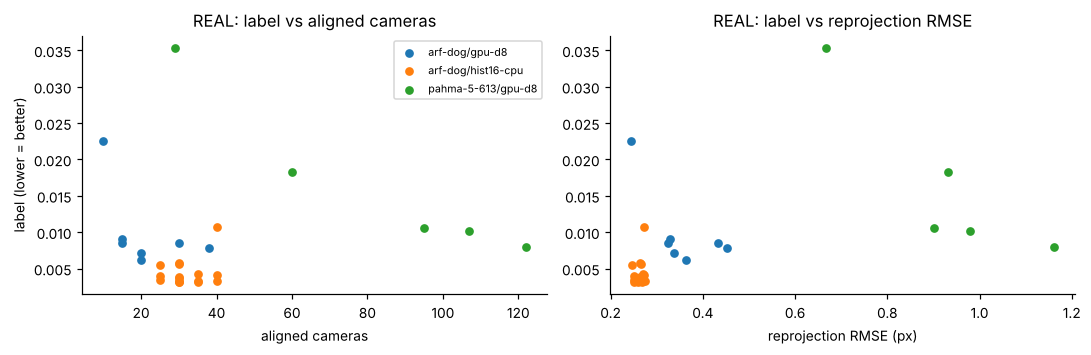

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
for g, d in real.groupby('group'):
    ax[0].scatter(d.n, d.label, label=g, s=22)
    ax[1].scatter(d.reproj, d.label, label=g, s=22)
ax[0].set(title='REAL: label vs aligned cameras', xlabel='aligned cameras', ylabel='label (lower = better)')
ax[1].set(title='REAL: label vs reprojection RMSE', xlabel='reprojection RMSE (px)')
ax[0].legend(fontsize=7)
plt.tight_layout()
for g, d in real.groupby('group'):
    print(f'{g:22s} Spearman(reproj, label) = {spearmanr(d.reproj, d.label).statistic:+.2f}  (n={len(d)})')

Three things to keep in mind for section 15: the groups barely overlap in camera count (dog 10–50, coffin
29–122), the label scale differs by group (each is relative to its own reference), and there are only 28
points, with builds from one capture sharing photos.

## 3. Camera positions, orientations, and pairwise geometry

The networks see positions $p_i$ (centred, scale-normalised) and, on real data, unit view directions $v_i$.
`gm.relations` turns them into three rotation-invariant pairwise quantities:

$$
d_{ij} = \lVert p_i - p_j \rVert, \qquad
c_{ij} = \hat r_i \cdot \hat r_j,\ \ \hat r = \frac{p}{\lVert p\rVert}, \qquad
u_{ij} = v_i \cdot v_j .
$$

$c_{ij}$ is the cosine of the angle between two cameras as seen from the object centre, so a coverage gap
shows up as a pair of azimuthal neighbours with unusually small $c_{ij}$.

To plot a build we need an "up" axis, which an unreferenced frame does not have. For a ring capture the normal
of the best-fit plane (smallest principal axis of the positions) is a good stand-in; azimuth is measured
around it. This is for plotting only; the models never use it.

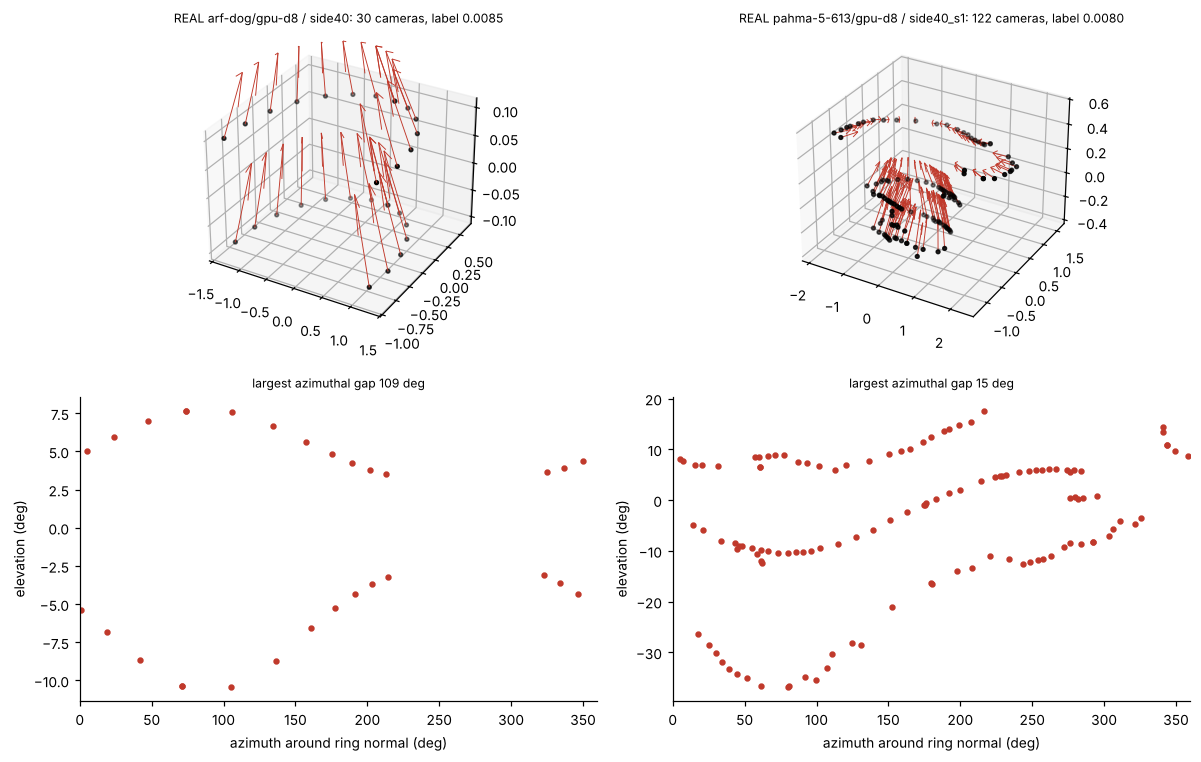

In [6]:
def frame(P):
    # Principal axes of the camera centres: the smallest-variance one is the ring normal ('up').
    w, U = np.linalg.eigh(np.cov(P.T))
    Q = U[:, ::-1]                    # largest, middle, smallest
    if np.linalg.det(Q) < 0: Q[:, 2] *= -1
    return P @ Q, Q

def azimuth_elevation(P):
    L, _ = frame(P)
    az = np.degrees(np.arctan2(L[:, 1], L[:, 0])) % 360
    el = np.degrees(np.arctan2(L[:, 2], np.linalg.norm(L[:, :2], axis=1)))
    return az, el

show = ['side40', 'side40_s1']      # dog GPU build and coffin build with one sector removed
fig = plt.figure(figsize=(11, 7))
for k, name in enumerate(show):
    r = next(r for r in runs if r['run'] == name)
    P, V = r['X'][:, :3], r['X'][:, 3:]
    L, Q = frame(P); VL = V @ Q
    ax = fig.add_subplot(2, 2, 1 + k, projection='3d')
    ax.quiver(L[:, 0], L[:, 1], L[:, 2], VL[:, 0], VL[:, 1], VL[:, 2], length=0.35, color=REAL, lw=0.6)
    ax.scatter(*L.T, s=6, c='k')
    ax.set_title(f'REAL {r["group"]} / {name}: {r["n"]} cameras, label {r["label"]:.4f}', fontsize=8)
    az, el = azimuth_elevation(P)
    ax2 = fig.add_subplot(2, 2, 3 + k)
    ax2.scatter(az, el, s=10, c=REAL)
    ax2.set(xlim=(0, 360), xlabel='azimuth around ring normal (deg)', ylabel='elevation (deg)')
    s = np.sort(az); gaps = np.diff(np.r_[s, s[0] + 360])
    ax2.set_title(f'largest azimuthal gap {gaps.max():.0f} deg', fontsize=8)
plt.tight_layout()

relations tensor shape for this build: (122, 122, 3) (N, N, R)


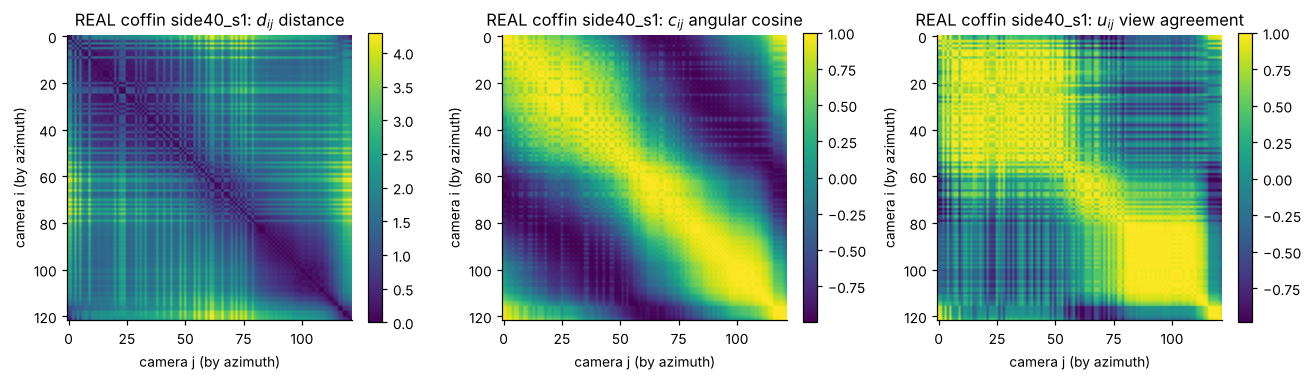

In [7]:
r = next(r for r in runs if r['run'] == 'side40_s1')
X = torch.tensor(r['X'])[None]
rel = gm.relations(X[..., :3], X[..., 3:], torch.ones(1, len(r['X']), dtype=torch.bool))[0].numpy()
order = np.argsort(azimuth_elevation(r['X'][:, :3])[0])        # sort cameras by azimuth for display
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, k, title in zip(axes, range(3), ['$d_{ij}$ distance', '$c_{ij}$ angular cosine', '$u_{ij}$ view agreement']):
    im = ax.imshow(rel[order][:, order, k], cmap='viridis')
    ax.set(title=f'REAL coffin side40_s1: {title}', xlabel='camera j (by azimuth)', ylabel='camera i (by azimuth)')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
print('relations tensor shape for this build:', rel.shape, '(N, N, R)')

The bright diagonal band in $c_{ij}$ is "my azimuthal neighbours". The 23 removed wall-level photos leave the
band thin in one stretch: exactly the structure a head with a geometric bias can attend to directly.

## 4. Neural network fundamentals and tensor dimensions

A batch of camera sets has different sizes, so it is padded to the largest set and carried with a boolean mask:

| tensor | shape | meaning |
|---|---|---|
| `X` | (B, N, 3) or (B, N, 6) | coordinates (+ view directions) |
| `M` | (B, N) | True for real cameras, False for padding |
| `rel` | (B, N, N, R) | pairwise relations, R = 2 (SIMULATED) or 3 (REAL) |
| output | (B,) | one prediction per set |

Each `nn.Linear(a, b)` computes $y = xW^\top + b$ on the **last** dimension, so it is applied to every camera
independently and shared across cameras. That weight sharing is what makes the per-camera encoder work for any N.

The cell below runs a real batch through the geo model and records every intermediate shape with forward hooks.

In [8]:
rng = np.random.default_rng(0)
Xb, Mb, yb = syn.build(rng, 4, 'localized')
Rb = gm.relations(Xb, None, Mb)
model = gm.make_model('geo', 3, 64, 2)
shapes = []
def hook(name):
    def f(mod, inp, out):
        o = out[0] if isinstance(out, tuple) else out
        shapes.append((name, type(mod).__name__, tuple(inp[0].shape), tuple(o.shape)))
    return f
for name, mod in [('embed', model.embed), ('attn', model.attn), ('attn.qkv', model.attn.qkv),
                  ('attn.bias (g)', model.attn.bias), ('attn.out', model.attn.out), ('ff', model.ff), ('rho', model.rho)]:
    mod.register_forward_hook(hook(name))
with torch.no_grad():
    y = model(Xb, Mb, Rb)
print('X', tuple(Xb.shape), ' M', tuple(Mb.shape), ' rel', tuple(Rb.shape), ' cameras per set:', Mb.sum(1).tolist())
display(pd.DataFrame(shapes, columns=['module', 'type', 'input shape', 'output shape']))
print('output', tuple(y.shape))
print(f'parameters: {gm.n_params(model):,}')

X (4, 60, 3)  M (4, 60)  rel (4, 60, 60, 2)  cameras per set: [26, 38, 24, 33]


,module,type,input shape,output shape
0,embed,Sequential,"(4, 60, 3)","(4, 60, 64)"
1,attn.qkv,Linear,"(4, 60, 64)","(4, 60, 192)"
2,attn.bias (g),Sequential,"(4, 60, 60, 2)","(4, 60, 60, 4)"
3,attn.out,Linear,"(4, 60, 64)","(4, 60, 64)"
4,attn,GeoAttention,"(4, 60, 64)","(4, 60, 64)"
5,ff,Sequential,"(4, 60, 64)","(4, 60, 64)"
6,rho,Sequential,"(4, 64)","(4, 1)"


output (4,)
parameters: 33,717


Reading the table: `attn.qkv` maps (4, 60, 64) → (4, 60, 192), i.e. Q, K, V stacked; `attn.bias (g)` maps the
(4, 60, 60, 2) relations to (4, 60, 60, 4), one bias per head per camera pair; the max-pool (not a module,
so not in the table) turns (4, 60, 64) into (4, 64) before `rho`.

## 5. PointNet

`gm.PointNetSet` (same as `PointNetSet` in `scripts/synthetic_coverage_gap.py`):

$$
\hat y = \rho\Big(\max_{i \le N} \phi(x_i)\Big), \qquad \phi,\rho:\ \text{2-layer MLPs.}
$$

The max is taken channel by channel over the cameras, so permuting cameras cannot change the result
(Zaheer et al., *Deep Sets*, 2017; Qi et al., *PointNet*, 2017). Gradients flow only to the camera that won
each channel. Limitation: $\phi$ sees one camera at a time, so a relational quantity such as "the gap between
my neighbours" can only be approximated through which cameras win which channels.

Below: the saved PointNet from notebook 03 (`runs/attention-maps/pointnet_localized_seed0.pt`, <span
style="color:#1f6feb">SIMULATED</span> localized, seed 0, 400 epochs, 3000 sets), a permutation check, and how
many of the 64 channels each camera wins.

PointNet prediction 124.79 deg, after shuffling cameras 124.79 deg, target 141.97 deg


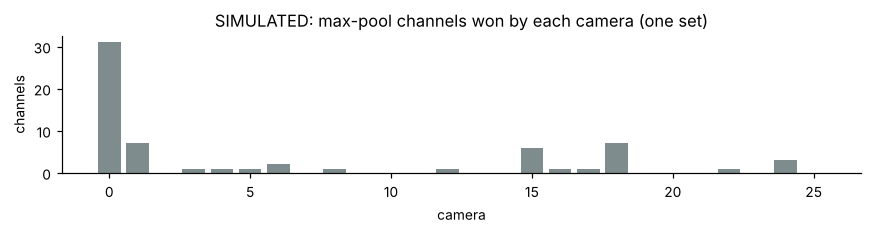

In [9]:
pnet = syn.PointNetSet(); pnet.load_state_dict(torch.load(REPO / 'runs/attention-maps/pointnet_localized_seed0.pt'))
attn = syn.AttnSet();     attn.load_state_dict(torch.load(REPO / 'runs/attention-maps/attention_localized_seed0.pt'))
pnet.eval(); attn.eval()

n0 = int(Mb[0].sum())
x, m = Xb[:1, :n0], Mb[:1, :n0]          # one set, padding removed
perm = torch.randperm(n0)
with torch.no_grad():
    a = pnet(x, m).item(); b = pnet(x[:, perm], m).item()
    feats = pnet.phi(x[0, :int(m.sum())])                 # (n, 64)
print(f'PointNet prediction {a*syn.SCALE:.2f} deg, after shuffling cameras {b*syn.SCALE:.2f} deg, target {yb[0]:.2f} deg')
wins = np.bincount(feats.argmax(0).numpy(), minlength=feats.shape[0])
plt.figure(figsize=(8, 2.2)); plt.bar(range(len(wins)), wins, color=COLOR['pointnet'])
plt.title('SIMULATED: max-pool channels won by each camera (one set)'); plt.xlabel('camera'); plt.ylabel('channels')
plt.tight_layout()

## 6. Standard multi-head self-attention

For tokens $F \in \mathbb{R}^{N\times h}$ (after `embed`), each head $k$ has its own projections:

$$
Q_k = F W^Q_k,\quad K_k = F W^K_k,\quad V_k = F W^V_k,\qquad W^\cdot_k \in \mathbb{R}^{h\times d},\ d = h/H
$$

$$
A_k = \operatorname{softmax}_j\!\left(\frac{Q_k K_k^\top}{\sqrt d}\right)\in\mathbb{R}^{N\times N},\qquad
\text{head}_k = A_k V_k,\qquad
\text{MHA}(F) = [\text{head}_1,\dots,\text{head}_H]\,W^O .
$$

Row $i$ of $A_k$ is a probability distribution over the cameras that camera $i$ reads from. Dividing by
$\sqrt d$ keeps the logits at unit variance when $q,k$ have unit-variance entries ($\operatorname{Var}(q\cdot k)=d$),
so the softmax does not saturate early in training (Vaswani et al., 2017). Padded keys get $-\infty$ before
the softmax and therefore zero weight.

`nn.MultiheadAttention` stores $[W^Q; W^K; W^V]$ stacked in `in_proj_weight` (shape 3h × h). The cell below
rebuilds Q, K, V and the attention matrices by hand from the saved model and checks them against PyTorch.

In [10]:
h, H = 64, 4; d = h // H
n = int(m.sum()); xx = x[:, :n]
with torch.no_grad():
    F = attn.embed(xx)                                               # (1, n, 64)
    Wq, Wk, Wv = attn.attn.in_proj_weight.split(h)                   # each (64, 64)
    bq, bk, bv = attn.attn.in_proj_bias.split(h)
    Q = (F @ Wq.T + bq).view(1, n, H, d).transpose(1, 2)             # (1, H, n, d)
    K = (F @ Wk.T + bk).view(1, n, H, d).transpose(1, 2)
    V = (F @ Wv.T + bv).view(1, n, H, d).transpose(1, 2)
    A_manual = torch.softmax(Q @ K.transpose(-1, -2) / math.sqrt(d), -1)   # (1, H, n, n)
    _, A_torch = attn.attn(F, F, F, need_weights=True, average_attn_weights=False)
print('Q, K, V shapes:', tuple(Q.shape), '| A shape:', tuple(A_manual.shape))
print('manual attention == nn.MultiheadAttention:', torch.allclose(A_manual, A_torch, atol=1e-6))
print('rows sum to 1:', torch.allclose(A_manual.sum(-1), torch.ones(1, H, n)))

Q, K, V shapes: (1, 4, 26, 16) | A shape: (1, 4, 26, 26)
manual attention == nn.MultiheadAttention: True
rows sum to 1: True


In [11]:
# Why divide by sqrt(d): softmax of logits whose spread grows with d.
z = torch.randn(10000, 32)
for dd in (4, 16, 64, 256):
    q, k = torch.randn(1000, dd), torch.randn(32, dd)
    raw = torch.softmax(q @ k.T, -1).max(-1).values.mean()
    scaled = torch.softmax(q @ k.T / math.sqrt(dd), -1).max(-1).values.mean()
    print(f'd={dd:3d}  mean max softmax weight over 32 keys: unscaled {raw:.2f}   scaled {scaled:.2f}')

d=  4  mean max softmax weight over 32 keys: unscaled 0.31   scaled 0.14
d= 16  mean max softmax weight over 32 keys: unscaled 0.63   scaled 0.16
d= 64  mean max softmax weight over 32 keys: unscaled 0.81   scaled 0.17
d=256  mean max softmax weight over 32 keys: unscaled 0.91   scaled 0.16


Without scaling the softmax becomes nearly one-hot as $d$ grows, and its gradient vanishes; with scaling it
stays soft at every width.

## 7. Geometry-aware attention

`gm.GeoAttention` changes one line: a learned bias is added to every head's logits.

$$
A_k = \operatorname{softmax}_j\!\left(\frac{Q_k K_k^\top}{\sqrt d} + B_k\right),\qquad
(B_k)_{ij} = g_k(r_{ij}),\qquad
g:\ \mathbb{R}^R \xrightarrow{\text{Linear}} \mathbb{R}^{16} \xrightarrow{\text{ReLU, Linear}} \mathbb{R}^{H}.
$$

$g$ is shared over all camera pairs, so it costs $R\cdot16+16+16H+H$ parameters (116 for R = 2, H = 4)
regardless of N. This is a *relative* geometric encoding, in the family of relative position bias (Shaw et al.
2018; Swin, Liu et al. 2021) and Graphormer's spatial encoding (Ying et al. 2021), here with continuous 3D
relations.

**Invariance.** For any rotation $R\in SO(3)$: $\lVert Rp_i - Rp_j\rVert = \lVert p_i-p_j\rVert$ and
$Rp_i\cdot Rp_j = p_i\cdot p_j$, so $B$ is exactly rotation-invariant
(`test_relations_are_rotation_invariant`). In `geo` the token inputs are still raw coordinates, so the model
as a whole is invariant only approximately (via augmentation). In `geo_inv` the tokens are $\lVert p_i\rVert$
(and $v_i\cdot\hat r_i$), so the whole model is invariant by construction (`test_geo_inv_model_is_rotation_invariant`).

**Why it could help.** A head that should "look at my azimuthal neighbours" needs logits that are large when
$c_{ij}\approx1$. Plain attention must produce that from $q_i\cdot k_j$ of embeddings of rotated coordinates;
with the bias, $g$ can produce it directly from $c_{ij}$.

The trained geo model below is `results/models/geo_localized_seed0.pt`, trained by `train_cached_models.py`
with the same data and settings as the saved attention model (localized, seed 0, 3000 sets, 400 epochs,
Adam 1e-3).

In [12]:
GEO_PT = RES / 'models' / 'geo_localized_seed0.pt'
if not GEO_PT.exists():
    raise FileNotFoundError('Run: python experiments/geometry-aware/train_cached_models.py  (about 11 min)')
ck = torch.load(GEO_PT, weights_only=False)
geo = gm.make_model('geo', ck['coord_dim'], ck['h'], ck['rel_dim']); geo.load_state_dict(ck['state_dict']); geo.eval()
print({k: v for k, v in ck.items() if k != 'state_dict'})
print(f"params: attention {sum(p.numel() for p in attn.parameters()):,}   geo {gm.n_params(geo):,}   "
      f"(bias MLP {sum(p.numel() for p in geo.attn.bias.parameters())})")

{'name': 'geo', 'coord_dim': 3, 'h': 64, 'rel_dim': 2, 'condition': 'localized', 'seed': 0, 'n_train': 3000, 'epochs': 400, 'lr': 0.001, 'test_mae_deg': 15.812097549438477, 'seconds': 652}
params: attention 33,601   geo 33,717   (bias MLP 116)


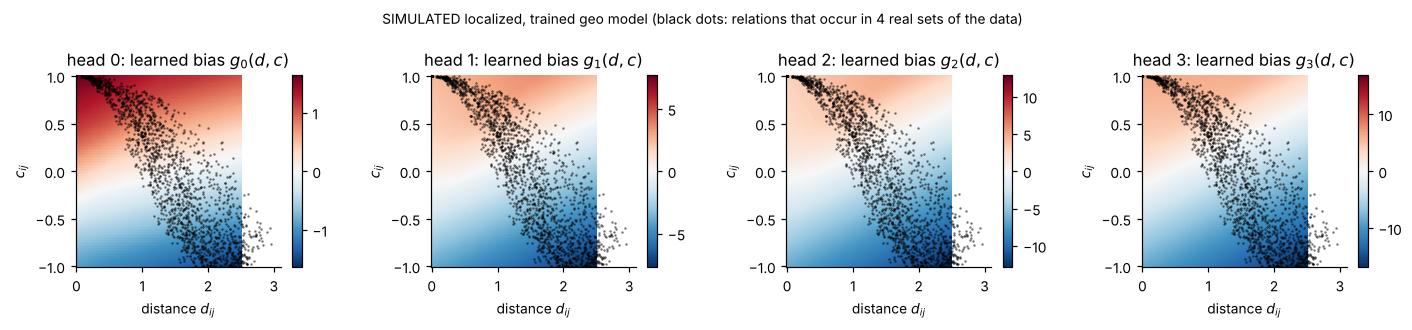

In [13]:
# The learned bias g_k(d, c) for each head, over the range of relations seen in training.
dd, cc = np.meshgrid(np.linspace(0, 2.5, 120), np.linspace(-1, 1, 120))
grid = torch.tensor(np.stack([dd, cc], -1), dtype=torch.float32)
with torch.no_grad():
    B = geo.attn.bias(grid).numpy()                    # (120, 120, H)
Rs = gm.relations(Xb, None, Mb)[Mb[:, :, None] & Mb[:, None, :]].numpy()   # observed (d, c) pairs
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for k, ax in enumerate(axes):
    im = ax.pcolormesh(dd, cc, B[..., k], cmap='RdBu_r', shading='auto',
                       vmin=-np.abs(B[..., k]).max(), vmax=np.abs(B[..., k]).max())
    ax.scatter(Rs[:, 0], Rs[:, 1], s=0.3, c='k', alpha=0.3)
    ax.set(title=f'head {k}: learned bias $g_{k}(d,c)$', xlabel='distance $d_{ij}$', ylabel='$c_{ij}$')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.suptitle('SIMULATED localized, trained geo model (black dots: relations that occur in 4 real sets of the data)', fontsize=9)
plt.tight_layout()

Only the region covered by black dots matters (on a sphere-like layout $d$ and $c$ are tied:
$d^2 = \lVert p_i\rVert^2+\lVert p_j\rVert^2-2\lVert p_i\rVert\lVert p_j\rVert c$). Red means "attend more to
pairs like this", blue "attend less".

**What it learned.** All four heads learned the same sign pattern: positive bias for pairs with $c_{ij}$ near 1
(cameras close in angle), negative for $c_{ij} < 0$ (cameras on opposite sides). Heads 1–3 use a large range
(about ±5 to ±15 logits, which dominates the content term), head 0 a small one (±1.5), so head 0 is left
mostly to the content-based $q\cdot k$. In words: "attend to your angular neighbours", learned from the
target alone.

## 8. Attention matrices: standard vs geometry-aware

Both models are trained on the same <span style="color:#1f6feb">SIMULATED</span> localized data (seed 0).
To interpret the matrices we need which ring each camera is on, its azimuth and where the hole is. `syn.make_set`
does not return those, so `make_set_meta` below draws a set with the same recipe (`syn.ring`, same ranges, same
frame randomisation) and keeps the metadata. It is a plotting helper, not used for any reported metric.

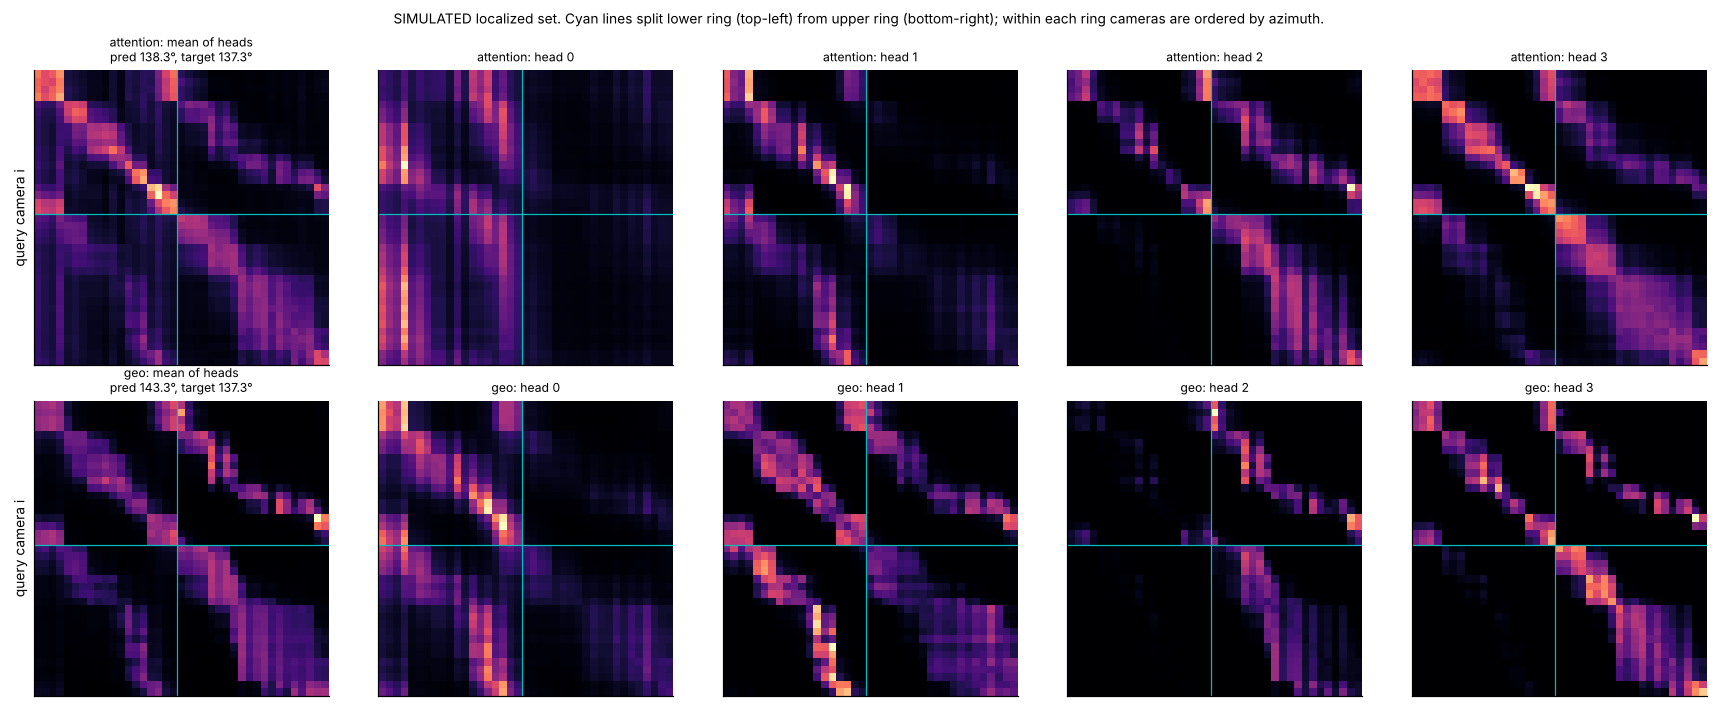

In [14]:
def make_set_meta(rng, hole_range=(60, 120)):
    hole, start = rng.uniform(*hole_range), rng.uniform(0, 360)
    n_lo, n_up = int(rng.integers(10, syn.NMAX // 2 + 1)), int(rng.integers(10, syn.NMAX // 2 + 1))
    p_lo, az_lo = syn.ring(rng, n_lo, 0, 15, 0.0, 0.0)
    p_up, az_up = syn.ring(rng, n_up, 40, 55, hole, start)
    p, az = np.r_[p_lo, p_up], np.r_[az_lo, az_up]
    upper = np.r_[np.zeros(n_lo, bool), np.ones(n_up, bool)]
    p = (p @ syn.random_rotation(rng).T) * rng.uniform(0.2, 5) + rng.normal(0, 10, 3)
    p = p - p.mean(0); p = p / np.median(np.linalg.norm(p, axis=1))
    return p.astype(np.float32), az, upper, syn.largest_gap(az_up)

@torch.no_grad()
def attention_maps(p):
    x = torch.tensor(p)[None]; mk = torch.ones(1, len(p), dtype=torch.bool)
    F = attn.embed(x); _, A_std = attn.attn(F, F, F, need_weights=True, average_attn_weights=False)
    G = geo.embed(x); _, A_geo = geo.attn(G, mk, gm.relations(x, None, mk), return_weights=True)
    pred_std = attn(x, mk).item() * syn.SCALE
    pred_geo = geo(x, mk, gm.relations(x, None, mk)).item() * syn.SCALE
    return A_std[0].numpy(), A_geo[0].numpy(), pred_std, pred_geo

p, az, upper, target = make_set_meta(np.random.default_rng(5))
A_std, A_geo, ps, pg = attention_maps(p)
order = np.lexsort((az, upper))                           # lower ring by azimuth, then upper ring by azimuth
n_lo = int((~upper).sum())
fig, axes = plt.subplots(2, 5, figsize=(16, 6.5))
for row, (A, name, pred) in enumerate([(A_std, 'attention', ps), (A_geo, 'geo', pg)]):
    mats = [A.mean(0)] + [A[k] for k in range(4)]
    for col, (ax, M_) in enumerate(zip(axes[row], mats)):
        ax.imshow(M_[order][:, order], cmap='magma', vmin=0)
        ax.axhline(n_lo - .5, c='c', lw=.8); ax.axvline(n_lo - .5, c='c', lw=.8)
        ax.set_title(f'{name}: ' + ('mean of heads' if col == 0 else f'head {col-1}') +
                     (f'\npred {pred:.1f}°, target {target:.1f}°' if col == 0 else ''), fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel('query camera i'); axes[1, 0].set_ylabel('query camera i')
plt.suptitle('SIMULATED localized set. Cyan lines split lower ring (top-left) from upper ring (bottom-right); '
             'within each ring cameras are ordered by azimuth.', fontsize=9)
plt.tight_layout()

A single set is an anecdote. The next cell measures, over 300 sets, how much attention weight goes to a key
as a function of its angular separation from the query, for both trained models. If the geometric bias is used
the way the hypothesis says, the geo model should put more weight on angular neighbours.

attention share of attention on cameras in the same ring: 0.64
geo       share of attention on cameras in the same ring: 0.64


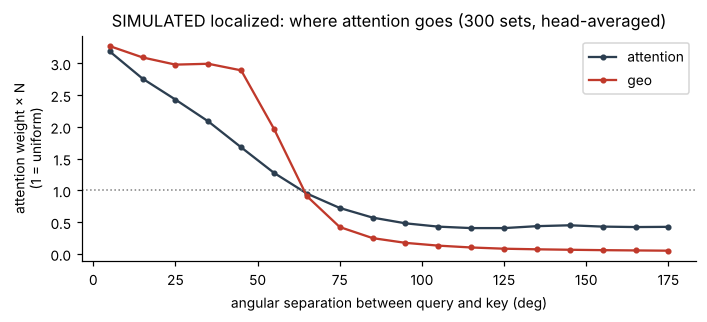

In [15]:
bins = np.linspace(0, 180, 19)
acc = {'attention': np.zeros(len(bins) - 1), 'geo': np.zeros(len(bins) - 1)}; cnt = np.zeros(len(bins) - 1)
same_ring = {'attention': [], 'geo': []}
rng = np.random.default_rng(11)
for _ in range(300):
    p, az, upper, _ = make_set_meta(rng, (0, 150))
    A_std, A_geo, *_ = attention_maps(p)
    r_ = p / np.linalg.norm(p, axis=1, keepdims=True)
    ang = np.degrees(np.arccos(np.clip(r_ @ r_.T, -1, 1)))
    idx = np.clip(np.digitize(ang, bins) - 1, 0, len(bins) - 2)
    np.add.at(cnt, idx.ravel(), 1)
    same = upper[:, None] == upper[None, :]
    for name, A in (('attention', A_std.mean(0)), ('geo', A_geo.mean(0))):
        np.add.at(acc[name], idx.ravel(), (A * len(p)).ravel())     # x N: 1.0 = uniform attention
        same_ring[name].append((A * same).sum(1).mean())
fig, ax = plt.subplots(figsize=(6.5, 3))
for name in acc:
    ax.plot((bins[:-1] + bins[1:]) / 2, acc[name] / np.maximum(cnt, 1), marker='o', ms=3, label=name, color=COLOR[name])
ax.axhline(1, c='gray', ls=':', lw=1)
ax.set(xlabel='angular separation between query and key (deg)', ylabel='attention weight × N\n(1 = uniform)',
       title='SIMULATED localized: where attention goes (300 sets, head-averaged)')
ax.legend(); plt.tight_layout()
for name in same_ring:
    print(f'{name:9s} share of attention on cameras in the same ring: {np.mean(same_ring[name]):.2f}')

**Reading.** Geo puts about 3× the uniform weight on keys within ~45° and almost none beyond 75°; standard
attention also prefers nearby cameras but decays gradually and keeps ~0.4× uniform weight on far cameras. Both
put the same share (0.64) on cameras of the query's own ring, so the bias changed *how local* attention is,
not *which ring* it reads. This is a measured description of two single-seed models, not a causal test.

## 9. Training methodology, loss, backpropagation, optimization

Source: `E.train_net` in `run_experiments.py`.

**Target scaling.** SIMULATED: degrees / 100. REAL: label / mean label of the training fold. Both put targets
near 1, so the default initialisation and learning rate are sensible.

**Loss.** Mean squared error, $\mathcal L(\theta) = \frac1B\sum_b(\hat y_b - y_b)^2$. Metrics are reported as MAE
and RMSE in the original units.

**Backpropagation.** Autograd applies the chain rule backwards through `rho` → max-pool (gradient only to the
winning camera per channel) → `ff` → residual → attention (through the softmax, $V$, and the logits, hence
$Q$, $K$ and, for geo, the bias MLP $g$) → `embed`.

**Optimiser.** Adam: per-parameter running means of the gradient $m_t$ and squared gradient $v_t$,
step $\theta \leftarrow \theta - \eta\,\hat m_t/(\sqrt{\hat v_t}+\epsilon)$.

| run | lr | schedule | batch | epochs | weight decay | augmentation |
|---|---|---|---|---|---|---|
| SIMULATED localized / count_shift | 3e-3 | cosine to 0 | 128 | 150 | 0 | fresh random rotation per set per step |
| SIMULATED long check, cached models | 1e-3 | constant | 128 | 400 | 0 | same |
| REAL | 1e-3 | constant | full fold | 400 | 1e-4 | same; test = mean over 8 random rotations |

`geo_inv` skips rotation augmentation because its inputs are already invariant. Networks are evaluated at the
last epoch; validation curves are recorded but not used to pick epochs. The cell below performs one real
training step and shows where the gradient goes.

In [16]:
torch.manual_seed(0)
net = gm.make_model('geo', 3, 64, 2)
opt = torch.optim.Adam(net.parameters(), lr=1e-3)
loss = nn.functional.mse_loss(net(Xb, Mb, Rb), yb / syn.SCALE)
opt.zero_grad(); loss.backward()
groups = {}
for name, prm in net.named_parameters():
    groups.setdefault(name.split('.')[0] + ('.bias-mlp' if '.bias.' in name else ''), []).append(prm.grad.norm().item())
print(f'loss before step {loss.item():.4f}')
display(pd.Series({k: float(np.sqrt(np.sum(np.square(v)))) for k, v in groups.items()}, name='gradient L2 norm'))
opt.step()
print(f'loss after one Adam step {nn.functional.mse_loss(net(Xb, Mb, Rb), yb / syn.SCALE).item():.4f}')

loss before step 1.8602


embed            0.325688
attn             0.158435
attn.bias-mlp    0.002663
ff               0.915617
rho              3.255272
Name: gradient L2 norm, dtype: float64

loss after one Adam step 1.7764


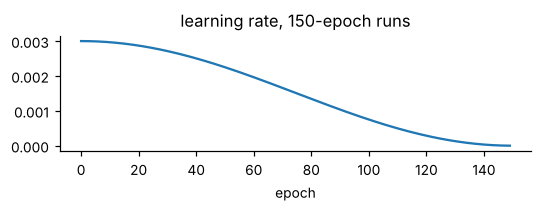

In [17]:
# The cosine schedule used for the 150-epoch runs.
o = torch.optim.Adam([torch.zeros(1, requires_grad=True)], lr=3e-3)
s = torch.optim.lr_scheduler.CosineAnnealingLR(o, 150); lrs = []
for _ in range(150): lrs.append(o.param_groups[0]['lr']); o.step(); s.step()
plt.figure(figsize=(5, 2)); plt.plot(lrs); plt.title('learning rate, 150-epoch runs'); plt.xlabel('epoch'); plt.tight_layout()

## 10. Training and validation curves

Saved during training every 10 epochs (`results/*/curves.csv`): training MSE on the scaled target, and
validation MAE in degrees. <span style="color:#1f6feb">SIMULATED</span> only: curves were not recorded for the
real-data runs (full-batch, 5 folds × 5 seeds × 5 nets), and this notebook does not reconstruct them.

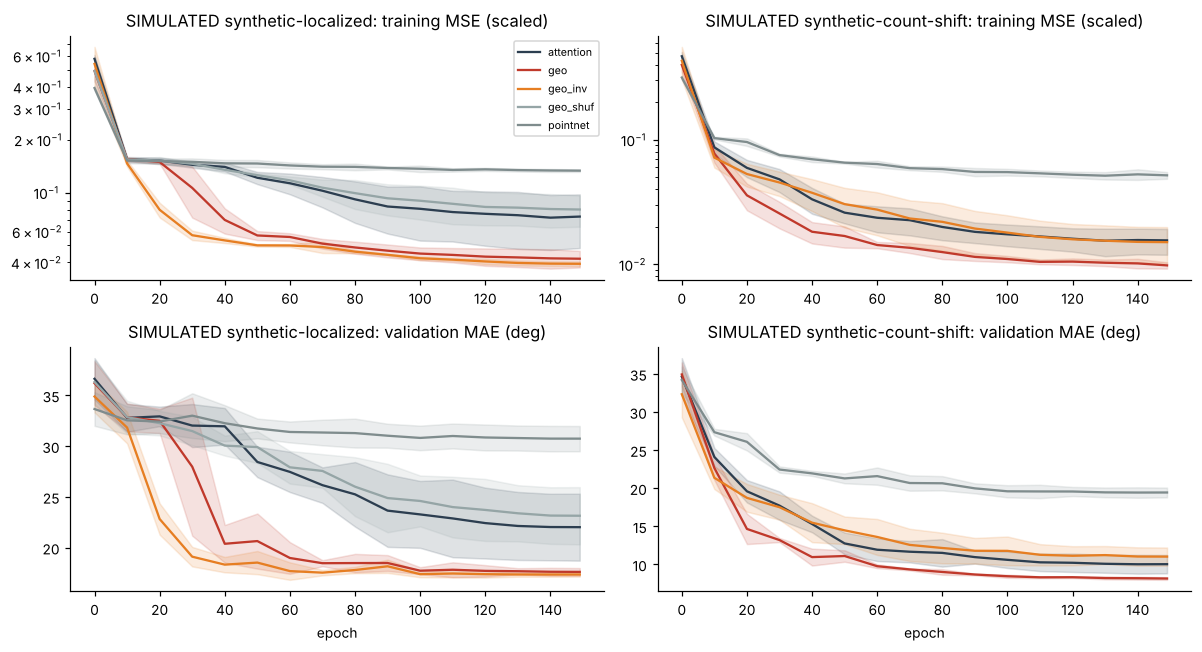

In [18]:
def load_curves(tag):
    return pd.read_csv(RES / tag / 'curves.csv')
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for col, tag in enumerate(['synthetic-localized', 'synthetic-count-shift']):
    c = load_curves(tag)
    for name, g in c.groupby('model'):
        s = g.groupby('epoch')[['train_mse', 'val_mae_deg']].agg(['mean', 'std'])
        for row, key in enumerate(['train_mse', 'val_mae_deg']):
            ax = axes[row, col]
            ax.plot(s.index, s[key]['mean'], label=name, color=COLOR.get(name))
            ax.fill_between(s.index, s[key]['mean'] - s[key]['std'], s[key]['mean'] + s[key]['std'],
                            color=COLOR.get(name), alpha=.15)
    axes[0, col].set(title=f'SIMULATED {tag}: training MSE (scaled)', yscale='log')
    axes[1, col].set(title=f'SIMULATED {tag}: validation MAE (deg)', xlabel='epoch')
axes[0, 0].legend(fontsize=7)
plt.tight_layout()

In count_shift the validation set has the **training** camera counts (20–35); the shift only appears at test
time (45–60), so these curves show in-distribution fit and section 14 shows the shift.

## 11. Baseline comparisons

Baselines (`E.fit_tabular`): Ridge, MLP and XGBoost on the rotation-invariant summaries of the original
scripts (count, covariance eigenvalues, radial mean/std, and on REAL data mean |view·radial|); `xgb_pair`
adds a 12-bin histogram of pairwise angular separations and nearest-neighbour angle statistics
(`E.pair_features`), so a tree model gets pairwise geometry without attention. SIMULATED tabular models are
tuned on the validation set; REAL ones use one fixed setting (no tuning on 28 points).
Error bars: standard deviation over seeds (3 SIMULATED, 5 REAL; deterministic models have none).

,condition,model,n_seeds,mae_mean,mae_std,rmse_mean,params
0,localized,mean,3,33.59,0.51,39.93,1.0
1,localized,ridge,3,27.70,0.82,33.75,NaN
2,localized,mlp,3,25.79,0.09,32.07,NaN
3,localized,xgb,3,26.01,0.53,32.08,NaN
4,localized,xgb_pair,3,21.88,0.64,27.27,NaN
5,localized,pointnet,3,30.51,0.29,36.89,8641.0
6,localized,attention,3,21.67,3.41,27.22,33601.0
7,localized,geo,3,17.51,0.49,22.58,33717.0
8,localized,geo_inv,3,17.25,0.58,22.35,33589.0
9,localized,geo_shuf,3,23.07,2.35,28.85,33717.0


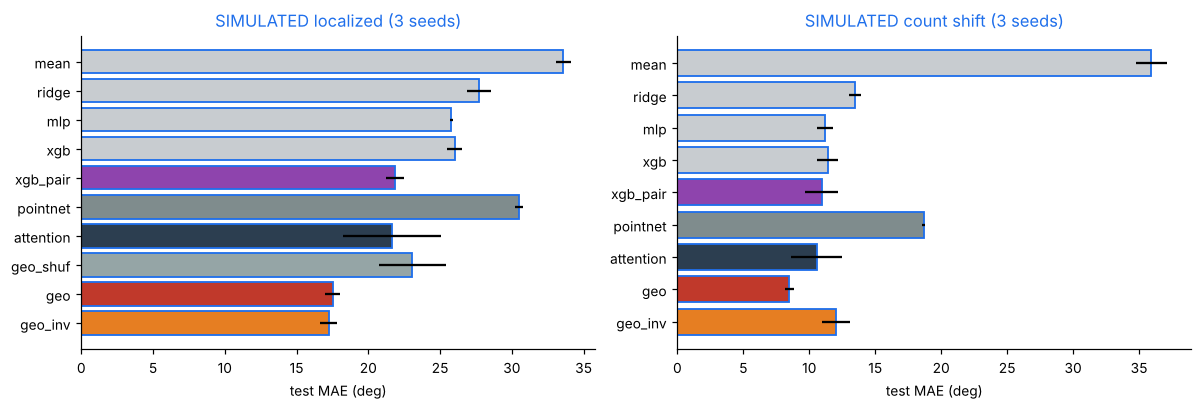

In [19]:
ORDER = ['mean', 'reproj', 'ridge', 'mlp', 'xgb', 'xgb_pair', 'pointnet', 'attention', 'geo_shuf', 'geo', 'geo_inv']
def barplot(ax, s, title, unit, color):
    s = s.set_index('model').reindex([m for m in ORDER if m in set(s.model)]).reset_index()
    ax.barh(s.model, s.mae_mean, xerr=s.mae_std, color=[COLOR.get(m, '#c8ccd0') for m in s.model],
            edgecolor=color, lw=1.2)
    ax.invert_yaxis(); ax.set_title(title, color=color); ax.set_xlabel(f'test MAE ({unit})')
syn_loc = pd.read_csv(RES / 'synthetic-localized/summary.csv')
syn_cs = pd.read_csv(RES / 'synthetic-count-shift/summary.csv')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
barplot(ax[0], syn_loc, 'SIMULATED localized (3 seeds)', 'deg', SIM)
barplot(ax[1], syn_cs, 'SIMULATED count shift (3 seeds)', 'deg', SIM)
plt.tight_layout()
pd.concat([syn_loc, syn_cs])[['condition', 'model', 'n_seeds', 'mae_mean', 'mae_std', 'rmse_mean', 'params']].round(2)

## 12. Shuffled-geometry ablation

`geo_shuf` is `geo` with each set's relation matrix permuted by the same random permutation on rows and
columns (`gm.shuffle_pairs`). The values of $d_{ij}, c_{ij}$ keep their distribution, but they describe the
wrong pairs. Same parameters, same compute. If `geo` beat `attention` only because of the extra MLP or the
extra compute, `geo_shuf` would too.

In [20]:
r_loc = pd.read_csv(RES / 'synthetic-localized/results.csv')
w = r_loc.pivot(index='seed', columns='model', values='mae')[['attention', 'geo_shuf', 'geo', 'geo_inv']]
w['geo − attention'] = w.geo - w.attention
w['geo − geo_shuf'] = w.geo - w.geo_shuf
display(w.round(2))
print('mean paired difference geo − geo_shuf: %.2f deg (all %d seeds negative: %s)'
      % (w['geo − geo_shuf'].mean(), len(w), bool((w['geo − geo_shuf'] < 0).all())))

model,attention,geo_shuf,geo,geo_inv,geo − attention,geo − geo_shuf
seed,,,,,,
0,25.59,23.94,18.02,16.58,-7.57,-5.92
1,19.95,24.86,17.46,17.59,-2.49,-7.40
2,19.46,20.41,17.04,17.57,-2.43,-3.38


mean paired difference geo − geo_shuf: -5.56 deg (all 3 seeds negative: True)


With 3 seeds this is a consistent direction, not a significance test. What it rules out is the capacity
explanation: the shuffled model has the same 33,717 parameters and is no better than plain attention.

## 13. Convergence and learning efficiency

Two views: epochs needed to reach a validation threshold in the 150-epoch runs, and the long check (400 epochs,
3000 sets, constant lr 1e-3, seed 0), which asks whether attention catches up when trained as long as the
original benchmark.

SIMULATED localized, 150-epoch runs: first epoch with validation MAE <= threshold, per seed (None = never)


threshold,18,20,25
model,,,
attention,"[nan, nan, nan]","[nan, nan, nan]","[nan, 80.0, 70.0]"
geo,"[100.0, 110.0, 80.0]","[40.0, 70.0, 40.0]","[40.0, 40.0, 30.0]"
geo_inv,"[40.0, 70.0, 50.0]","[30.0, 40.0, 30.0]","[20.0, 20.0, 20.0]"
geo_shuf,"[nan, nan, nan]","[nan, nan, nan]","[100.0, nan, 80.0]"
pointnet,"[nan, nan, nan]","[nan, nan, nan]","[nan, nan, nan]"


,model,mae_mean,rmse_mean
0,mean,32.80,39.26
1,ridge,27.24,33.06
2,mlp,25.13,30.85
3,xgb,25.15,30.89
4,xgb_pair,21.18,26.85
5,attention,16.06,20.34
6,geo,15.81,20.53


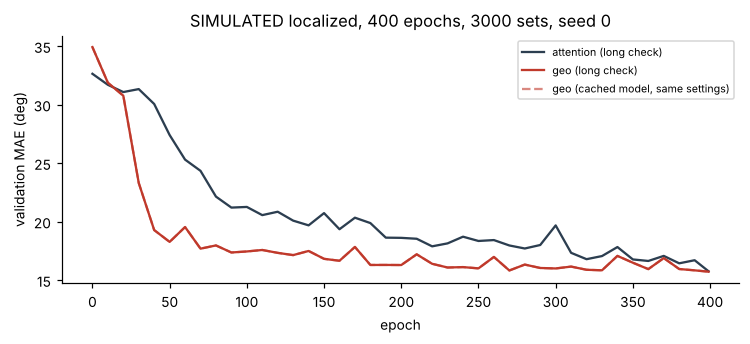

In [21]:
c = load_curves('synthetic-localized')
rows = []
for (name, seed), g in c.groupby(['model', 'seed']):
    for thr in (25, 20, 18):
        hit = g[g.val_mae_deg <= thr]
        rows.append(dict(model=name, seed=seed, threshold=thr, epoch=int(hit.epoch.min()) if len(hit) else None))
t = pd.DataFrame(rows).pivot_table(index='model', columns='threshold', values='epoch', aggfunc=lambda v: list(v))
print('SIMULATED localized, 150-epoch runs: first epoch with validation MAE <= threshold, per seed (None = never)')
display(t)

long = load_curves('synthetic-localized-long')
cached = pd.read_csv(RES / 'models/geo_localized_seed0_curve.csv')
fig, ax = plt.subplots(figsize=(7, 3.2))
for name, g in long.groupby('model'):
    ax.plot(g.epoch, g.val_mae_deg, label=f'{name} (long check)', color=COLOR[name])
ax.plot(cached.epoch, cached.val_mae_deg, ls='--', color=COLOR['geo'], alpha=.6, label='geo (cached model, same settings)')
ax.set(xlabel='epoch', ylabel='validation MAE (deg)', title='SIMULATED localized, 400 epochs, 3000 sets, seed 0')
ax.legend(fontsize=7); plt.tight_layout()
display(pd.read_csv(RES / 'synthetic-localized-long/summary.csv')[['model', 'mae_mean', 'rmse_mean']].round(2))

**Reading.** In the 150-epoch runs geo reaches 20° validation MAE by epoch 40–70 in every seed; attention
never gets below 20° within 150 epochs, and reaches 25° only in 2 of 3 seeds. With 400 epochs and 3000 sets
the picture changes:

| model (localized, seed 0, 400 epochs, 3000 sets) | test MAE |
|---|---|
| geo (`run_all.sh` long check, and the cached model: identical) | 15.81° |
| attention, my implementation (`gm.AttnSet`, rel_dim = 0) | 16.06° |
| attention, original implementation (`runs/attention-maps/attention_localized_seed0.pt`) | 13.09° (section 16) |
| attention, original implementation, 5 seeds (README) | 13.99 ± 1.06° |

The two attention implementations compute the same function but initialise differently: `nn.MultiheadAttention`
uses Xavier-uniform input projections and zero biases, `gm.GeoAttention` uses PyTorch's default `nn.Linear`
initialisation. All comparisons in sections 11–14 use the same implementation for attention, geo and
geo_shuf, so they are internally fair; but the 3-point gap above shows the original attention is likely
**more accurate than geo at convergence**. So H1 holds only as **sample and compute efficiency and
stability**; at full training, geo has not been shown to match the original attention. Testing that needs geo
with the Xavier initialisation, 400 epochs and 5 seeds (about 55 min on 2 CPU threads).

## 14. Camera-count distribution shift

Train and validate on sets of 20–35 cameras; test on 45–60. This mimics moving from the dog captures
(10–50 cameras) to the coffin (29–122). Section 2a shows the two count distributions do not overlap.

,model,mae_mean,mae_std
0,mean,35.92,1.19
1,ridge,13.48,0.45
2,mlp,11.19,0.63
3,xgb,11.39,0.78
4,xgb_pair,10.94,1.26
5,pointnet,18.66,0.13
6,attention,10.56,1.95
7,geo,8.47,0.35
8,geo_inv,12.02,1.07


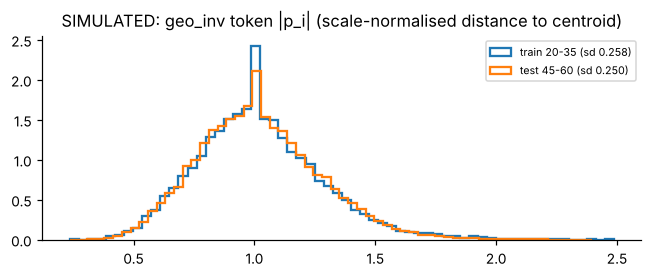

In [22]:
display(syn_cs[['model', 'mae_mean', 'mae_std']].round(2))
# Why can the fully invariant model struggle? Its only per-camera input is |p_i|. Compare its distribution.
rng = np.random.default_rng(3)
norms = {lab: np.concatenate([np.linalg.norm(E.make_set_n(rng, a, b)[0], axis=1) for _ in range(400)])
         for lab, (a, b) in {'train 20-35': (20, 35), 'test 45-60': (45, 60)}.items()}
plt.figure(figsize=(6, 2.6))
for lab, v in norms.items():
    plt.hist(v, bins=60, histtype='step', density=True, lw=1.5, label=f'{lab} (sd {v.std():.3f})')
plt.title('SIMULATED: geo_inv token |p_i| (scale-normalised distance to centroid)'); plt.legend(fontsize=7); plt.tight_layout()

geo keeps the lowest error under the shift (8.5° vs 10.6° attention, 10.9° best tree model), at 150 epochs.
geo_inv, which tied geo in-distribution, falls to 12.0°. The obvious suspect, a shift in its only token
feature, is ruled out by the histogram: $\lVert p_i\rVert$ has nearly the same distribution at both camera
counts (sd 0.258 vs 0.250). Why geo_inv degrades is untested. One candidate is that with 1-dimensional tokens
all of its information has to pass through the relations and the softmax, whose weights spread thinner over
more cameras; checking that would need attention-entropy measurements at both counts.

Caveat: these are 150-epoch runs with my attention implementation (see section 13).

## 15. <span style="color:#c0392b">REAL</span> data: evaluation and the limits of cross-object generalization

Splits (`E.run_real`): **LOGO**, leave one capture group out (dog-CPU 16, dog-GPU 7, coffin 5), and **LOAO**,
leave one object out (2 folds). Leave-one-build-out is not used for conclusions because builds from one
capture share photos. Settings match `scripts/pilot_set_models.py`.

scheme,LOAO,LOGO
model,,
mean,0.01082,0.00735
reproj,0.03945,0.00691
ridge,0.02365,0.01389
mlp,0.01519,0.01228
xgb,0.01907,0.00456
xgb_pair,0.02128,0.00506
pointnet,0.00407,0.00508
attention,0.00411,0.00497
geo_shuf,0.00363,0.00450


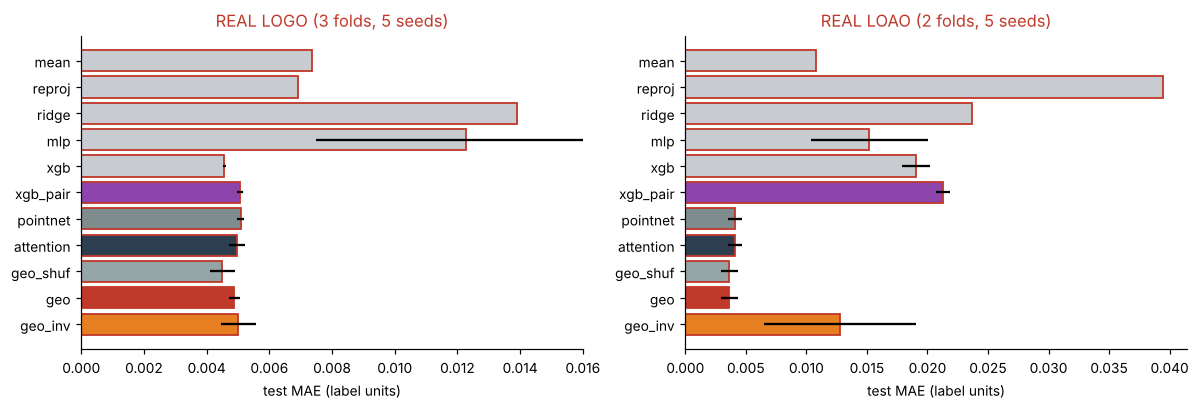

In [23]:
real_sum = pd.read_csv(RES / 'real/summary.csv')
pred = pd.read_csv(RES / 'real/predictions.csv')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
barplot(ax[0], real_sum[real_sum.scheme == 'LOGO'], 'REAL LOGO (3 folds, 5 seeds)', 'label units', REAL)
barplot(ax[1], real_sum[real_sum.scheme == 'LOAO'], 'REAL LOAO (2 folds, 5 seeds)', 'label units', REAL)
ax[0].set_xlim(0, 0.016); plt.tight_layout()
real_sum.pivot(index='model', columns='scheme', values='mae_mean').reindex(ORDER).dropna(how='all').round(5)

<cell>:8: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  tab[mdl][f'{fold} Spearman'] = spearmanr(g.predicted, g.actual).statistic


,arf-dog MAE,arf-dog Spearman,pahma-5-613 MAE,pahma-5-613 Spearman
mean,0.0109,NaN,0.0104,NaN
reproj,0.0460,-0.3962,0.0091,-0.9000
ridge,0.0145,0.5929,0.0658,0.7000
xgb,0.0215,-0.2250,0.0078,-0.4617
pointnet,0.0033,0.3962,0.0072,0.3000
attention,0.0034,0.3636,0.0069,0.3000
geo,0.0028,0.3379,0.0068,0.3000
geo_shuf,0.0028,0.4644,0.0067,0.3000


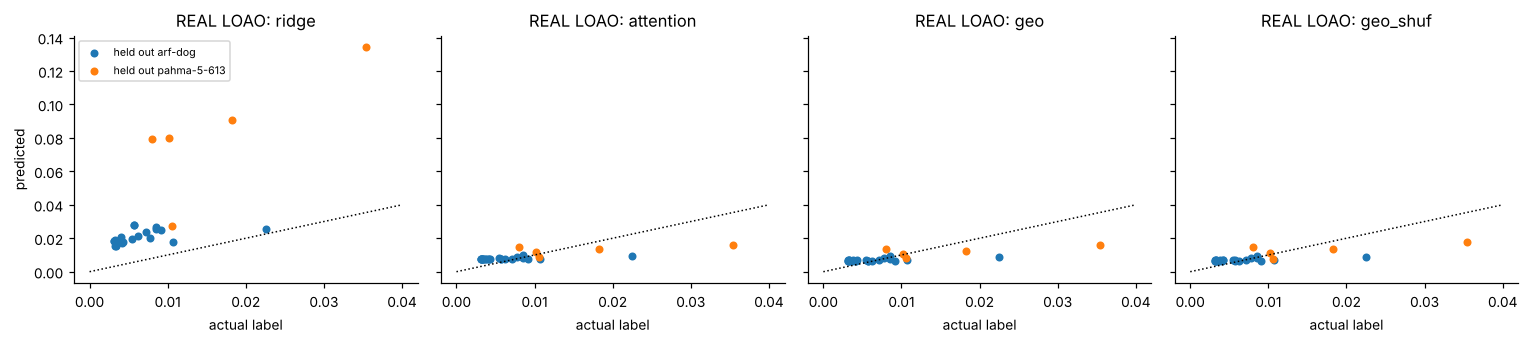

In [24]:
# Per fold, and rank correlation inside each held-out object (prediction averaged over seeds).
models = ['mean', 'reproj', 'ridge', 'xgb', 'pointnet', 'attention', 'geo', 'geo_shuf']
P = pred[pred.scheme == 'LOAO'].groupby(['held_out', 'model', 'run'], as_index=False)[['predicted', 'actual']].mean()
tab = {}
for (fold, mdl), g in P.groupby(['held_out', 'model']):
    if mdl in models:
        tab.setdefault(mdl, {})[f'{fold} MAE'] = (g.predicted - g.actual).abs().mean()
        tab[mdl][f'{fold} Spearman'] = spearmanr(g.predicted, g.actual).statistic
display(pd.DataFrame(tab).T.reindex(models).round(4))

fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharex=True, sharey=True)
for ax, mdl in zip(axes, ['ridge', 'attention', 'geo', 'geo_shuf']):
    g = P[P.model == mdl]
    for fold, gg in g.groupby('held_out'):
        ax.scatter(gg.actual, gg.predicted, s=18, label=f'held out {fold}')
    lim = [0, 0.04]; ax.plot(lim, lim, 'k:', lw=1); ax.set(title=f'REAL LOAO: {mdl}', xlabel='actual label')
axes[0].set_ylabel('predicted'); axes[0].legend(fontsize=7); plt.tight_layout()

**What the real data can and cannot say.**

- The set networks (PointNet, attention, geo, geo_shuf) overlap within one standard deviation under both
  splits, and geo is no better than its shuffled control. With 28 builds and 2 objects the data cannot show an
  effect of geometry-aware attention, in either direction.
- Under LOAO the networks have the lowest MAE, but inside each held-out object Ridge **ranks** builds best
  (ρ ≈ +0.59 dog, +0.70 coffin) while the networks rank them weakly. Ridge's error is a wrong overall *level*
  on the new object (look at its scatter: right ordering, shifted). MAE across objects mixes level and ranking;
  for choosing between captures of one object, ranking is what matters.
- The original "~6× lower error on an unseen object" was attention vs Ridge under LOAO: it reflects this level
  effect on 2 folds, not evidence that attention judges builds better.
- 5 coffin builds make every coffin statistic fragile.

## 16. Failure analysis, conclusions, and future directions

### Where the trained models fail (<span style="color:#1f6feb">SIMULATED</span>)

The saved attention model and the cached geo model were trained on the same data (localized, seed 0), so the
seed-0 **test set** (600 sets, regenerated exactly by `E.synthetic_data`) gives a paired, per-example
comparison. These are single-seed models; treat them as a case study.

test MAE (deg): {'pointnet': 27.88, 'attention': 13.09, 'geo': 15.81}


,attention,geo,pointnet,sets
target bin,,,,
"(30, 60]",7.9,16.700001,41.900002,58
"(60, 90]",10.0,13.300000,23.299999,164
"(90, 120]",13.3,15.500000,13.000000,146
"(120, 180]",15.7,16.000000,33.500000,210


share of sets where geo has the smaller error: 0.45


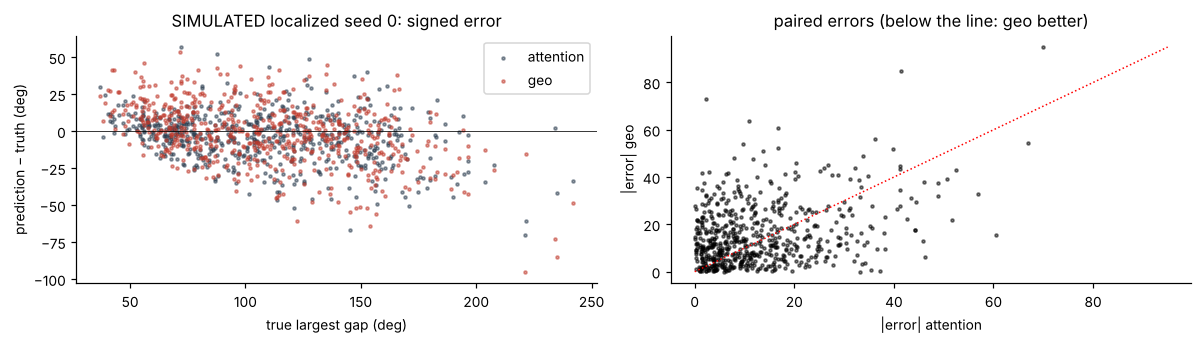

In [25]:
(_, _, _), (_, _, _), (Xte, Mte, yte) = E.synthetic_data('localized', 0, 3000, 600, 600)
Rte = gm.relations(Xte, None, Mte)
with torch.no_grad():
    p_att = attn(Xte, Mte) * syn.SCALE
    p_geo = E.predict(geo, 'geo', Xte, Mte, Rte, False, 0) * syn.SCALE
    p_pn = pnet(Xte, Mte) * syn.SCALE
err = pd.DataFrame({'target': yte.numpy(), 'n': Mte.sum(1).numpy(), 'attention': (p_att - yte).numpy(),
                    'geo': (p_geo - yte).numpy(), 'pointnet': (p_pn - yte).numpy()})
print('test MAE (deg):', {k: round(float(err[k].abs().mean()), 2) for k in ('pointnet', 'attention', 'geo')})
err['target bin'] = pd.cut(err.target, [0, 30, 60, 90, 120, 180])
display(err.groupby('target bin', observed=True)[['attention', 'geo', 'pointnet']]
        .agg(lambda e: e.abs().mean()).round(1).assign(sets=err.groupby('target bin', observed=True).size()))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for k in ('attention', 'geo'):
    ax[0].scatter(err.target, err[k], s=4, alpha=.5, label=k, color=COLOR[k])
ax[0].axhline(0, c='k', lw=.5); ax[0].set(xlabel='true largest gap (deg)', ylabel='prediction − truth (deg)',
                                           title='SIMULATED localized seed 0: signed error')
ax[1].scatter(err.attention.abs(), err.geo.abs(), s=4, alpha=.5, c='k')
lim = [0, max(err.attention.abs().max(), err.geo.abs().max())]; ax[1].plot(lim, lim, 'r:', lw=1)
ax[1].set(xlabel='|error| attention', ylabel='|error| geo', title='paired errors (below the line: geo better)')
ax[0].legend(); plt.tight_layout()
print('share of sets where geo has the smaller error: %.2f' % (err.geo.abs() < err.attention.abs()).mean())

In [26]:
# REAL: the builds every set network gets most wrong under LOAO.
net_err = (P[P.model.isin(['pointnet', 'attention', 'geo'])]
           .assign(abs_err=lambda d: (d.predicted - d.actual).abs())
           .groupby('run').agg(actual=('actual', 'first'), mean_abs_err=('abs_err', 'mean')))
net_err.join(real.set_index('run')[['group', 'n', 'reproj']]).sort_values('mean_abs_err', ascending=False).head(6).round(4)

,actual,mean_abs_err,group,n,reproj
run,,,,,
random30_s20261111,0.0354,0.0204,pahma-5-613/gpu-d8,29,0.6661
random10,0.0225,0.0138,arf-dog/gpu-d8,10,0.2452
random60_s20261112,0.0182,0.0058,pahma-5-613/gpu-d8,60,0.9325
side40_s1,0.0080,0.0056,pahma-5-613/gpu-d8,122,1.1614
arf-dog-image-count-30-seed-20260823-v1,0.0031,0.0041,arf-dog/hist16-cpu,30,0.2599
arf-dog-structured-uniform-30-v1,0.0032,0.0041,arf-dog/hist16-cpu,30,0.2506


**Reading.** On this seed the original attention model is better overall (13.1° vs 15.8°) and much better on
small gaps (30–60°: 7.9° vs 16.7°); geo has the smaller error on only 45% of sets. The two are close on large
gaps. So the geometric bias, as trained here, is not uniformly better per example; its advantage in sections
11–13 is about how fast and how reliably it gets to a good model.

### Conclusions

1. **H1, supported only as efficiency (SIMULATED).** At a matched 150-epoch budget, geometry-aware attention
   cuts error on the localized task from 21.7 ± 3.4° to 17.5 ± 0.5° and is far more stable across seeds. At
   400 epochs the original attention implementation reaches 13.1° on the same seed (14.0 ± 1.1° over 5 seeds)
   against geo's 15.8°, so geo is faster to train but has not been shown to be as accurate at convergence.
2. **H2, supported (SIMULATED).** Under the camera-count shift geo has the lowest error (8.5 ± 0.3° vs
   10.6 ± 1.9°). The fully invariant variant does not share this.
3. **H3, supported (SIMULATED).** The shuffled-geometry control, with identical capacity, loses the benefit.
4. **REAL: no conclusion about architecture is possible at n = 28.** The measurable real finding is about
   evaluation: cross-object MAE rewards getting the level right, while within-object ranking, the useful
   quantity, is best for the simplest model.

### Decisions to be able to defend

| decision | reason |
|---|---|
| bias on the logits, not extra token features | relations are pairwise, tokens are per camera; a bias keeps the cost at ~100 parameters and keeps Q/K/V unchanged |
| d, c, u as relations | rotation-invariant (exact), cheap, and directly tied to coverage |
| shuffled control | separates "geometry" from "more parameters / compute" |
| fixed epoch budget + long check | the budget could favour the faster learner, so it was tested; it did |
| LOGO / LOAO, not leave-one-build-out | builds of one capture share photos |
| Spearman inside held-out objects | MAE across objects mixes level and ranking |

### Future directions (in order)

0. **Close the convergence question**: geo with `nn.MultiheadAttention`'s Xavier initialisation, 400 epochs,
   5 seeds, against the README's 13.99 ± 1.06°.
1. **More real builds and objects.** The bottleneck is labels, not architecture: LOAO with 2 folds cannot rank models.
2. **Report within-object ranking with every real result.**
3. **Richer relations and tokens** once data allows: full relative pose (relative rotation, baseline / depth
   ratio), tokens that survive count shift.
4. **Learned image features** (e.g. frozen DINOv2 per photo) as token inputs next to geometry.
5. **Score learned reconstruction too** (DUSt3R, VGGT) and ask whether the same predictor transfers.
6. **Localized prediction**: where geometry will be missing, not one number per build; then
   **next-best view**: pick the camera that most reduces predicted error.

### References

Vaswani et al., *Attention Is All You Need*, 2017. Qi et al., *PointNet*, 2017. Zaheer et al., *Deep Sets*,
2017. Lee et al., *Set Transformer*, 2019. Shaw et al., *Self-Attention with Relative Position
Representations*, 2018. Liu et al., *Swin Transformer*, 2021. Ying et al., *Do Transformers Really Perform Bad
for Graph Representation?* (Graphormer), 2021.